# Customers Like You
Run `python build_matrix.py` first, then this notebook top to bottom.

ML1 decision (before fitting): Truncated SVD. It works on the sparse matrix directly and gives product factors for the recommender in one fit. PCA (the comparison in ML5) has to centre the data, which breaks sparsity.

In [1]:
import json, time, tracemalloc
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from scipy.sparse.linalg import norm as sparse_norm
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

SEED = 42
D = "data/processed/"
A = sp.load_npz(D + "A.npz")
products = pd.read_csv(D + "products.csv", dtype={"stock_code": str})
name = products["description"].values
country = pd.read_csv(D + "customer_country.csv")["country"].values
cust_row = dict(pd.read_csv(D + "customers.csv")[["customer_id", "row"]].values)
prod_col = dict(zip(products["stock_code"], products["col"]))
test = pd.read_csv(D + "test.csv", dtype={"StockCode": str})

# held-out products per test customer, as matrix indices
held = test.assign(r=test["Customer ID"].map(cust_row), c=test["StockCode"].map(prod_col)) \
           .groupby("r")["c"].apply(set)
rows = held.index.values
print(json.load(open(D + "matrix_report.json")))
print("test customers:", len(rows))

{'customers': 5473, 'products': 3687, 'non_zeros': 413927, 'sparsity_%': 97.95, 'dense_MB': 161.4, 'sparse_MB': 5.0, 'train_cutoff': '2011-10-09', 'purchase_value': 'log1p(quantity)', 'min_customers_per_product': 10}
test customers: 1913


## ML3/ML4 helpers
Customer scores use the dot product, not cosine. Cosine lost to the baseline (~23% vs 27%) because it drops popularity.

In [2]:
# top-n unbought products per customer from the rank-k scores
def recommend(A, V, rows, n=10, mean=None):
    X = A[rows].toarray()
    if mean is None:
        S = (X @ V) @ V.T
    else:
        S = mean + ((X - mean) @ V) @ V.T
    S[X > 0] = -np.inf
    return np.argsort(-S, axis=1)[:, :n]

# share of customers with at least one held-out product in their top-n
def hit_rate(recs, rows):
    return np.mean([len(set(r) & held[u]) > 0 for r, u in zip(recs, rows)])

# n products most similar to product j (cosine)
def similar(P, j, n=10):
    s = P @ P[j]
    s[j] = -np.inf
    return np.argsort(-s)[:n]

popularity = np.asarray((A > 0).sum(axis=0)).ravel()
top_sellers = np.argsort(-popularity)

# top-n best sellers each customer has not bought
def baseline_recs(A, rows, n=10):
    out = []
    for u in rows:
        bought = set(A[u].indices)
        out.append([j for j in top_sellers[:n + len(bought)] if j not in bought][:n])
    return out

base_hr = hit_rate(baseline_recs(A, rows), rows)
print(f"Best-seller baseline hit rate@10: {base_hr:.1%}")

Best-seller baseline hit rate@10: 26.9%


## ML2: fit for each k, reconstruction error and hit rate

In [3]:
normA2 = sparse_norm(A) ** 2
res = []
for k in [10, 20, 50, 100, 200]:
    t = time.time()
    svd = TruncatedSVD(n_components=k, random_state=SEED).fit(A)
    fit_s = time.time() - t
    err = np.sqrt(1 - (svd.singular_values_ ** 2).sum() / normA2)   # ||A - A_k|| / ||A||
    hr = hit_rate(recommend(A, svd.components_.T, rows), rows)
    res.append((k, fit_s, err, hr))
res = pd.DataFrame(res, columns=["k", "fit_s", "rel_error", "hit_rate@10"])
res

,k,fit_s,rel_error,hit_rate@10
0,10,0.095306,0.875917,0.302143
1,20,0.112481,0.845705,0.349712
2,50,0.314352,0.789583,0.378463
3,100,0.764522,0.727785,0.388918
4,200,1.542581,0.639466,0.397804


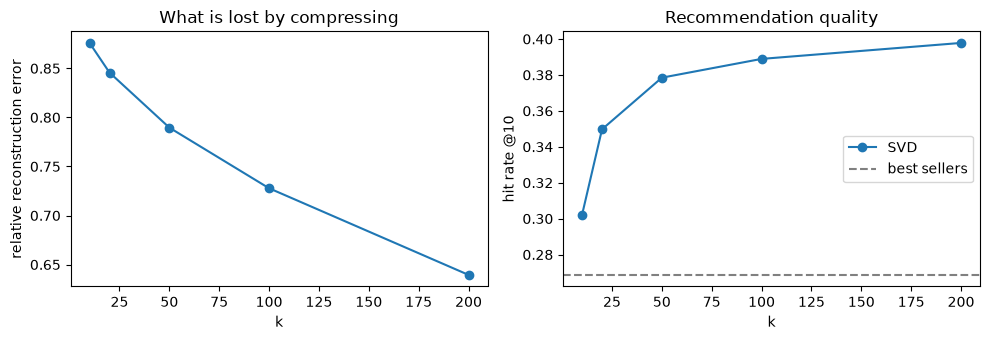

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(res.k, res.rel_error, "o-")
ax[0].set(xlabel="k", ylabel="relative reconstruction error", title="What is lost by compressing")
ax[1].plot(res.k, res["hit_rate@10"], "o-", label="SVD")
ax[1].axhline(base_hr, color="gray", ls="--", label="best sellers")
ax[1].set(xlabel="k", ylabel="hit rate @10", title="Recommendation quality"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/k_curve.png", dpi=150); plt.show()

k: smallest k within 1 point of the best hit rate. Larger k costs more for no gain.

In [5]:
K = int(res.loc[res["hit_rate@10"] >= res["hit_rate@10"].max() - 0.01, "k"].min())
print("chosen k =", K)

chosen k = 100


## ML3/ML4: final model, example recommendations, nightly job timing

In [6]:
tracemalloc.start()
t = time.time()
svd = TruncatedSVD(n_components=K, random_state=SEED).fit(A)
svd_fit = time.time() - t
svd_peak = tracemalloc.get_traced_memory()[1] / 1e6
tracemalloc.stop()

V = svd.components_.T                     # product factors
P = normalize(V)                          # unit length, for cosine product-to-product similarity
U = svd.transform(A)                      # customer factors (U S)

# nightly job = top-10 similar products for every product + top-10 recs for every customer
t = time.time()
sim_table = np.argsort(-(P @ P.T), axis=1)[:, 1:11]
all_recs = np.vstack([recommend(A, V, np.arange(i, min(i + 1000, A.shape[0])))
                      for i in range(0, A.shape[0], 1000)])
score_s = time.time() - t

svd_hr = hit_rate(recommend(A, V, rows), rows)
svd_mb = (U.nbytes + V.nbytes) / 1e6
print(f"fit {svd_fit:.1f}s + scoring {score_s:.1f}s | factors {svd_mb:.1f} MB | "
      f"hit rate {svd_hr:.1%} vs baseline {base_hr:.1%}")

fit 0.6s + scoring 1.1s | factors 7.3 MB | hit rate 38.9% vs baseline 26.9%


In [7]:
# example product page box
j = int(top_sellers[0])
print("Customers who bought", name[j], "also bought:")
for i in similar(P, j): print("  -", name[i])

Customers who bought WHITE HANGING HEART T-LIGHT HOLDER also bought:
  - RED HANGING HEART T-LIGHT HOLDER
  - CANDLEHOLDER PINK HANGING HEART
  - RED HANGING METAL STAR TLIGHT HLDR
  - CREAM HEART CARD HOLDER
  - COLOUR GLASS. STAR T-LIGHT HOLDER
  - JAZZ HEARTS SPIRAL NOTEPAD
  - WHITE METAL LANTERN
  - GLASS STAR FROSTED T-LIGHT HOLDER
  - SCALLOP SHELL SOAP DISH
  - BLUE GINGHAM ROSE QUILT 


## ML5: PCA with the same k on the same matrix

In [8]:
tracemalloc.start()
t = time.time()
pca = PCA(n_components=K, svd_solver="arpack", random_state=SEED).fit(A)
pca_fit = time.time() - t
pca_peak = tracemalloc.get_traced_memory()[1] / 1e6
tracemalloc.stop()

V_pca = pca.components_.T
U_pca = pca.transform(A)
pca_hr = hit_rate(recommend(A, V_pca, rows, mean=pca.mean_), rows)
pca_mb = (U_pca.nbytes + V_pca.nbytes + pca.mean_.nbytes) / 1e6

volume = np.asarray(A.sum(axis=1)).ravel()
print("corr(comp1, volume): SVD %.2f, PCA %.2f" % (abs(np.corrcoef(U[:, 0], volume)[0, 1]),
                                                abs(np.corrcoef(U_pca[:, 0], volume)[0, 1])))

corr(comp1, volume): SVD 0.97, PCA 0.97


In [9]:
svd_err = np.sqrt(1 - (svd.singular_values_ ** 2).sum() / normA2)
comparison = pd.DataFrame({
    "PCA": [K, f"{pca_fit:.1f}", f"{pca_peak:.0f}", f"{pca_mb:.1f}",
            f"{pca.explained_variance_ratio_.sum():.1%} variance explained", f"{pca_hr:.1%}", f"{base_hr:.1%}",
            "difference from the average customer"],
    "Truncated SVD": [K, f"{svd_fit:.1f}", f"{svd_peak:.0f}", f"{svd_mb:.1f}",
            f"{svd_err:.1%} relative reconstruction error", f"{svd_hr:.1%}", f"{base_hr:.1%}",
            "overall buying volume (how much a customer buys)"],
}, index=["k used", "Fit time (s)", "Peak memory during fit (MB)", "Size of stored factors (MB)",
          "Variance explained / reconstruction error", "Hit rate@10 held-out",
          "Best-seller baseline hit rate@10", "Component 1 in words"])
comparison.to_csv("figures/pca_vs_svd.csv")
comparison

,PCA,Truncated SVD
k used,100,100
Fit time (s),0.6,0.6
Peak memory during fit (MB),15,18
Size of stored factors (MB),7.4,7.3
Variance explained / reconstruction error,44.9% variance explained,72.8% relative reconstruction error
Hit rate@10 held-out,38.5%,38.9%
Best-seller baseline hit rate@10,26.9%,26.9%
Component 1 in words,difference from the average customer,overall buying volume (how much a customer buys)


## ML6: customer map
K-means (5 groups) on unit-length customer factors. Plotted on components 2 and 3, since component 1 is just volume.

In [10]:
Un = normalize(U)
km = KMeans(n_clusters=5, random_state=SEED, n_init=10).fit(Un)
seg = km.labels_

for s in range(km.n_clusters):
    m = seg == s
    top_p = np.argsort(-np.asarray(A[m].sum(axis=0)).ravel())[:6]
    top_c = pd.Series(country[m]).value_counts(normalize=True).head(3)
    print(f"Segment {s} ({m.sum()} customers)")
    print("  products:", "; ".join(name[top_p]))
    print("  countries:", ", ".join(f"{c} {v:.0%}" for c, v in top_c.items()))

Segment 0 (1853 customers)
  products: REGENCY CAKESTAND 3 TIER; STRAWBERRY CERAMIC TRINKET BOX; ASSORTED COLOUR BIRD ORNAMENT; GRAND CHOCOLATECANDLE; PARTY BUNTING; ANTIQUE SILVER TEA GLASS ETCHED
  countries: United Kingdom 94%, Germany 1%, France 1%
Segment 1 (1144 customers)
  products: WHITE HANGING HEART T-LIGHT HOLDER; ASSORTED COLOUR BIRD ORNAMENT; HEART OF WICKER SMALL; HEART OF WICKER LARGE; ZINC METAL HEART DECORATION; RED HANGING HEART T-LIGHT HOLDER
  countries: United Kingdom 97%, Cyprus 0%, Spain 0%
Segment 2 (1086 customers)
  products: WORLD WAR 2 GLIDERS ASSTD DESIGNS; VINTAGE SNAP CARDS; MINI PAINT SET VINTAGE ; VINTAGE HEADS AND TAILS CARD GAME ; PACK OF 12 TRADITIONAL CRAYONS; RED  HARMONICA IN BOX 
  countries: United Kingdom 87%, Germany 3%, France 3%
Segment 3 (701 customers)
  products: PACK OF 72 RETRO SPOT CAKE CASES; 60 TEATIME FAIRY CAKE CASES; PACK OF 60 PINK PAISLEY CAKE CASES; PACK OF 60 DINOSAUR CAKE CASES; 72 SWEETHEART FAIRY CAKE CASES; PACK OF 72 SKU

In [11]:
# named from the top products and countries printed above
SEGMENT_NAMES = {0: "Home & party decor", 1: "Hanging hearts & rustic decor", 2: "Vintage toys & games",
                 3: "Home bakers (cake cases)", 4: "Bags & lunch bags"}

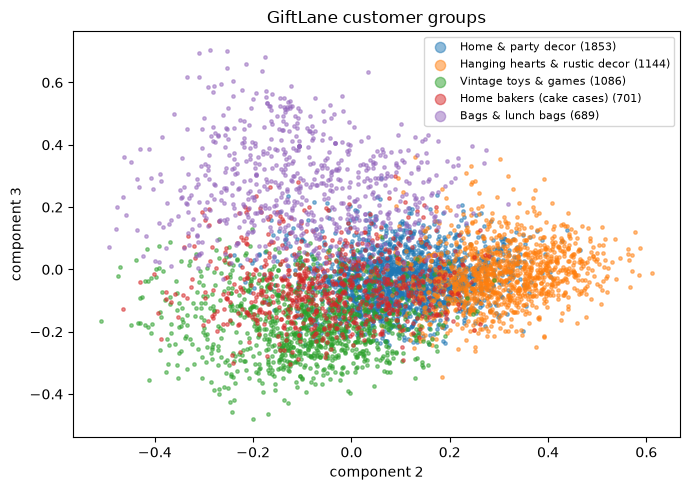

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
for s in range(km.n_clusters):
    m = seg == s
    ax.scatter(Un[m, 1], Un[m, 2], s=6, alpha=0.5, label=f"{SEGMENT_NAMES[s]} ({m.sum()})")
ax.set(xlabel="component 2", ylabel="component 3", title="GiftLane customer groups")
ax.legend(markerscale=3, fontsize=8); plt.tight_layout(); plt.savefig("figures/customer_map.png", dpi=150); plt.show()

## ML7: sensitivity to the purchase value

In [13]:
train = pd.read_csv(D + "train.csv", dtype={"StockCode": str})
r, c = train["Customer ID"].map(cust_row), train["StockCode"].map(prod_col)
for label, v in [("count", train["Quantity"]), ("1/0", np.ones(len(train))), ("log(1+q)", np.log1p(train["Quantity"]))]:
    Av = sp.csr_matrix((v, (r, c)), shape=A.shape)
    Vv = TruncatedSVD(n_components=K, random_state=SEED).fit(Av).components_.T
    print(f"{label:9s} hit rate@10 = {hit_rate(recommend(Av, Vv, rows), rows):.1%}")

count     hit rate@10 = 22.4%


1/0       hit rate@10 = 40.3%


log(1+q)  hit rate@10 = 38.9%


## Findings
- SVD beats the best-seller baseline. PCA ties with it, so we keep SVD (it stays sparse).
- Dot-product scoring is what makes the difference. With cosine scoring both methods lose.
- 1/0 values beat log(1+q) slightly. Raw counts are worst.